# 01 — EFH Cleaning

Cleans `Base imputada EFH 2021.dta`, computes `net_wealth = act_fin + cap_pen_ent + act_real - d_toth`, and saves `data/processed/efh_2021_clean.{csv,parquet}`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import os

from utils import load_root
ROOT = load_root()

from source import figures as figplot

%load_ext autoreload
%autoreload 2

[utils] Project root loaded successfully: /home/choroy/Documents/doctorado/S4/ENECO894/problem-set


In [2]:
FIGURES_OUT = ROOT / 'figures'
DATA_OUT = ROOT / 'data/processed/'

### EFH 2021 

source = https://www.bcentral.cl/areas/encuestas-economicas/encuesta-financiera-de-hogares

$$\text{net wealth} = \text{real assets} + \text{financial assets} + \text{pension assets} - \text{total liabilities}$$

In [3]:
efh_df = pd.read_stata(os.path.join(ROOT, 'data/EFH/Base imputada EFH 2021.dta'))
nanvalues = efh_df[['act_toth','d_toth','factor']].isna()
efh_df_clean = efh_df.dropna(subset=['act_toth','d_toth','factor'])
print(nanvalues.sum(), 1-efh_df_clean.shape[0]/efh_df.shape[0], efh_df_clean.shape[0], efh_df.shape[0])

act_toth    1051
d_toth       546
factor         0
dtype: int64 0.010381231671554247 134984 136400


In [4]:
# correct net_wealth as in Stata: act_fin + cap_pen + act_real - d_toth
efh_df_clean['act_real'] = efh_df_clean[['act_vp','act_otp','act_vehic','act_otros']].sum(axis=1, skipna=True)
efh_df_clean['net_wealth'] = efh_df_clean['act_fin'].fillna(0) + efh_df_clean['cap_pen_ent'].fillna(0) + efh_df_clean['act_real'].fillna(0) - efh_df_clean['d_toth'].fillna(0)

In [5]:
efh_df_clean['net_wealth'].describe()

count    1.349840e+05
mean     1.135645e+08
std      2.169936e+08
min     -2.981307e+08
25%      1.124017e+07
50%      5.200000e+07
75%      1.220498e+08
max      4.931589e+09
Name: net_wealth, dtype: float64

saved figure to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set/figures/netwealth-efh.pdf


PosixPath('/home/choroy/Documents/doctorado/S4/ENECO894/problem-set/figures/netwealth-efh.pdf')

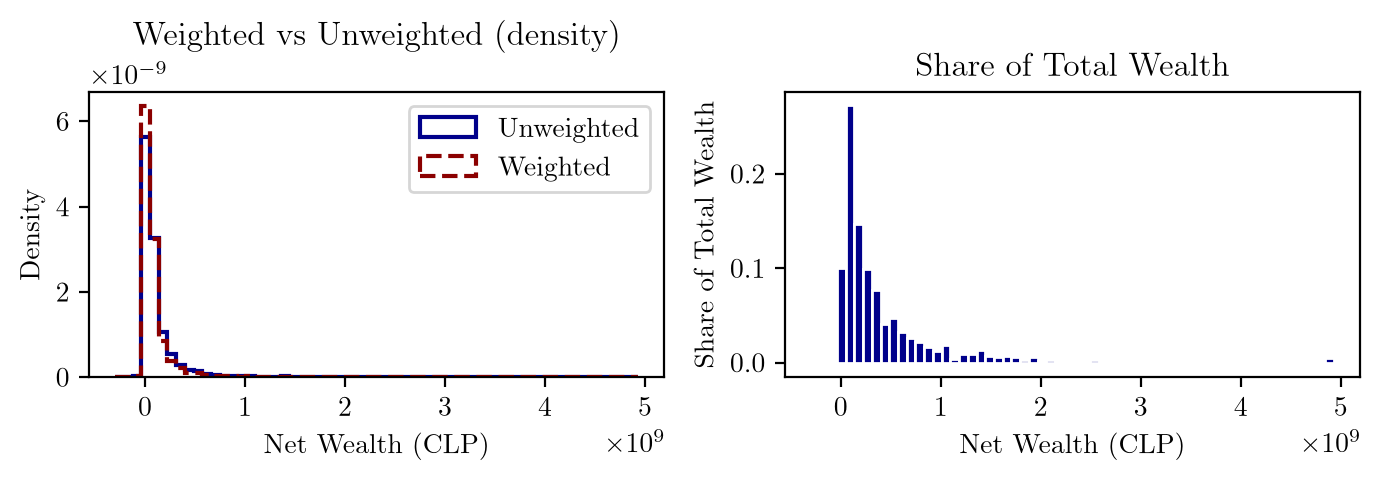

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(7, 2.5), dpi=200)
fig, ax0 = figplot.plot_wealth_weighted_vs_unweighted(efh_df_clean, fig, axes[0], wealth_col='net_wealth', weight_col='factor', bins=60)
ax0.set_title("Weighted vs Unweighted (density)")
fig, ax1 = figplot.plot_wealth_distribution(efh_df_clean, fig, axes[1], wealth_col='net_wealth', weight_col='factor', bins=60, normalize=True)
ax1.set_title("Share of Total Wealth")
# fig.suptitle("Wealth Distribution 2021 --- EFH", y=0.95)
fig.tight_layout()
figplot.save_fig(FIGURES_OUT / 'netwealth-efh.pdf', fig, dpi=300)


### Save data for next steps

In [7]:
# Save data for next steps — only columns needed for Q2 (shares)
DATA_OUT.mkdir(parents=True, exist_ok=True)

# need act components + pension for correct net_wealth (Stata: act_fin + cap_pen + act_real - d_toth)
cols_needed = ['id','factor','net_wealth','act_toth','d_toth','act_vp','act_otp','act_vehic','act_otros','act_fin','act_ahcta','cap_pen_ent']
cols_needed = [c for c in cols_needed if c in efh_df_clean.columns]
efh_out = efh_df_clean[cols_needed].copy()
efh_out.to_csv(DATA_OUT / 'efh_2021_clean.csv', index=False)
try:
    efh_out.to_parquet(DATA_OUT / 'efh_2021_clean.parquet', index=False)
except Exception as e:
    print(f"parquet skip: {e}")
print(f"saved EFH to {DATA_OUT / 'efh_2021_clean.csv'} — shape {efh_out.shape} cols {cols_needed}")


saved EFH to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set/data/processed/efh_2021_clean.csv — shape (134984, 12) cols ['id', 'factor', 'net_wealth', 'act_toth', 'd_toth', 'act_vp', 'act_otp', 'act_vehic', 'act_otros', 'act_fin', 'act_ahcta', 'cap_pen_ent']
